In [69]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import MonthLocator, DateFormatter

In [70]:
df = pd.read_csv("/Users/jonas/Desktop/mails.csv")
df

,id,folderID,messageKey,conversationID,date,headerMessageID,deleted,jsonAttributes,notability
0,32,NaN,NaN,1,1.762524e+15,fe274e5b-cfc0-4765-9bd8-038e8ac4e872@students....,1,"{""43"":1,""44"":[1],""45"":[],""46"":[],""50"":false,""5...",11
1,33,14.0,9.0,2,1.691129e+15,IO0X1XYUMKU4.5Z2IAFF2YYVQ@appweb26,0,"{""43"":2,""44"":[1],""45"":[],""46"":[],""50"":false,""5...",19
2,34,NaN,NaN,3,NaN,ZR1P278MB1071380381AA7D5A85C8D02AAB36A@ZR1P278...,0,NaN,0
3,35,NaN,NaN,3,NaN,ZR0P278MB03488ED73540C779FA8665758E01A@ZR0P278...,0,NaN,0
4,36,14.0,22.0,3,1.691071e+15,GV0P278MB08075AA2C0614C87AB79C06C9C08A@GV0P278...,0,"{""43"":3,""44"":[4],""45"":[],""46"":[],""50"":false,""5...",18
...,...,...,...,...,...,...,...,...,...
1371,1403,14.0,574.0,951,1.696973e+15,c7fe5eaa-054a-4068-a019-fe0bd2dc74c4@AM3PEPF00...,0,"{""43"":7,""44"":[1],""45"":[],""46"":[],""50"":false,""5...",19
1372,1404,14.0,566.0,952,1.696950e+15,ZR0P278MB047666E6F5FC745CD24780BA9DCDA@ZR0P278...,0,"{""43"":59,""44"":[4],""45"":[],""46"":[],""49"":[16385]...",18
1373,1405,NaN,NaN,953,NaN,CANYzPMo4VRQLyLqA3VPxHA_8wuhnSJmkTSytWhYXjVqN2...,0,NaN,0
1374,1406,14.0,12858.0,953,1.762535e+15,ZRAP278MB0029005ED403DE6D7468CCA98DC3A@ZRAP278...,0,"{""43"":154,""44"":[155],""45"":[1015,1069],""46"":[],...",22


In [71]:
df_date = df.copy()
df_date["date"] = pd.to_datetime(df_date["date"], unit='us', errors='coerce')  # 'us' = microseconds
df_date.dropna(subset=["date"], inplace=True)
df_date

,id,folderID,messageKey,conversationID,date,headerMessageID,deleted,jsonAttributes,notability
0,32,NaN,NaN,1,2025-11-07 13:59:28,fe274e5b-cfc0-4765-9bd8-038e8ac4e872@students....,1,"{""43"":1,""44"":[1],""45"":[],""46"":[],""50"":false,""5...",11
1,33,14.0,9.0,2,2023-08-04 06:05:05,IO0X1XYUMKU4.5Z2IAFF2YYVQ@appweb26,0,"{""43"":2,""44"":[1],""45"":[],""46"":[],""50"":false,""5...",19
4,36,14.0,22.0,3,2023-08-03 14:02:01,GV0P278MB08075AA2C0614C87AB79C06C9C08A@GV0P278...,0,"{""43"":3,""44"":[4],""45"":[],""46"":[],""50"":false,""5...",18
10,42,14.0,46.0,4,2023-08-13 19:32:49,GV0P278MB0807BCCAB84E70B769EA8EEB9C16A@GV0P278...,0,"{""43"":3,""44"":[4],""45"":[5],""46"":[],""49"":[16385]...",20
11,43,14.0,199.0,5,2023-09-13 07:09:39,GV0P278MB0686F9B0DA5AE0F02C6C0A68C8F0A@GV0P278...,0,"{""43"":6,""44"":[6],""45"":[],""46"":[],""50"":false,""5...",10
...,...,...,...,...,...,...,...,...,...
1370,1402,14.0,579.0,950,2023-10-11 08:07:50,ZR0P278MB047671C4101434C22C792CE59DCCA@ZR0P278...,0,"{""43"":59,""44"":[4],""45"":[59,82],""46"":[],""49"":[1...",20
1371,1403,14.0,574.0,951,2023-10-10 21:22:28,c7fe5eaa-054a-4068-a019-fe0bd2dc74c4@AM3PEPF00...,0,"{""43"":7,""44"":[1],""45"":[],""46"":[],""50"":false,""5...",19
1372,1404,14.0,566.0,952,2023-10-10 15:07:51,ZR0P278MB047666E6F5FC745CD24780BA9DCDA@ZR0P278...,0,"{""43"":59,""44"":[4],""45"":[],""46"":[],""49"":[16385]...",18
1374,1406,14.0,12858.0,953,2025-11-07 17:07:24,ZRAP278MB0029005ED403DE6D7468CCA98DC3A@ZRAP278...,0,"{""43"":154,""44"":[155],""45"":[1015,1069],""46"":[],...",22


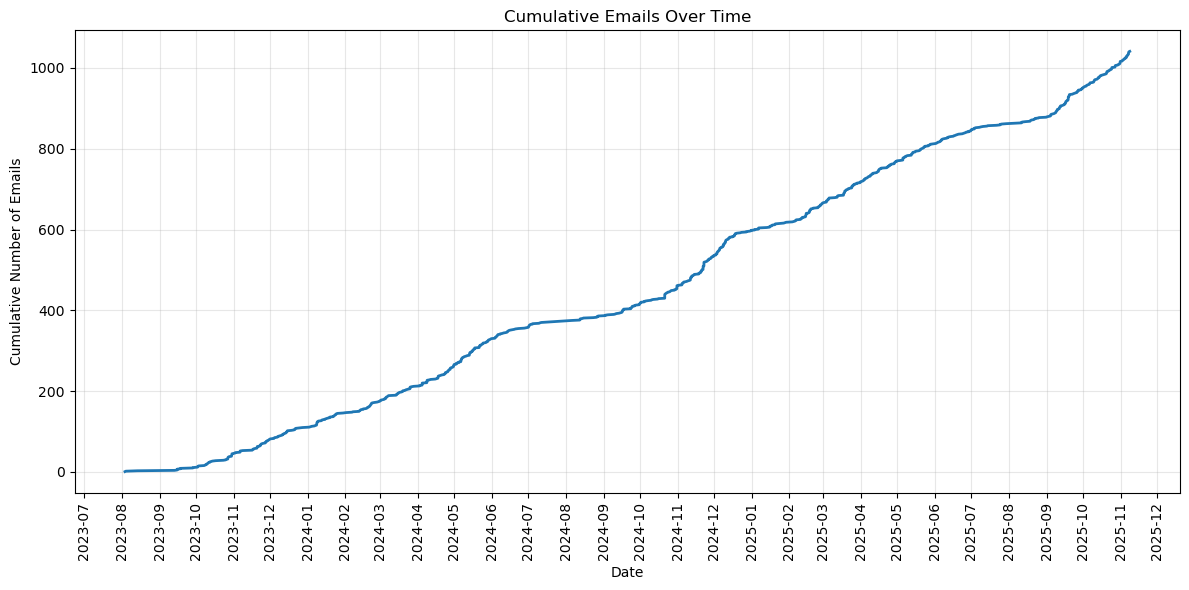

In [72]:
# Assuming df_date is already loaded with a 'date' column
# Count emails per date and calculate cumulative sum
email_counts = df_date['date'].value_counts().sort_index()
cumulative_emails = email_counts.cumsum()

# Create the line plot
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(cumulative_emails.index, cumulative_emails.values, linewidth=2)
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Number of Emails')
ax.set_title('Cumulative Emails Over Time')

# Set major grid lines at every month
ax.xaxis.set_major_locator(MonthLocator())
ax.xaxis.set_major_formatter(DateFormatter('%Y-%m'))

# Enable grid
ax.grid(True, alpha=0.3, which='major')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [73]:
# average mails per day
df_date['date_only'] = df_date['date'].dt.date
average_mails_per_day = df_date.groupby('date_only').size().mean()
average_mails_per_day

2.2778993435448576